# 과제2. 투자 포트폴리오 제안 및 최종 송금 승인 시스템
- 실습 목표 : Memory, Interrupt(Time Travel), 멀티 에이전트(Supervisor/Subgraph)
- 흐름 : `load_memory` → `supervisor` ⇄ `market_analyst`(Subgraph, State 분리) / `portfolio_planner`(Subgraph, State 공유) → `human_review`(interrupt) → `guardrail` → `execute_transfer` → END
- 시장 데이터는 실습용 가상 데이터이며 실제 송금/매매는 발생하지 않음

## 요구사항 → 구현 위치
| 요구사항 | 구현 |
|---|---|
| 1. Supervisor + Subgraph | `supervisor`(LLM 라우팅 + 선행조건 코드 가드), `market_analyst`·`portfolio_planner` 서브그래프 |
| 2. 공통 State / 장기 메모리 | `PortfolioState`, `InMemoryStore` 의 `(user_id, "profile" / "history")` |
| 3. Human-in-the-loop | `human_review` 의 `interrupt()` + 입력 검증 루프, `Command(resume=...)` 로 approve / reject |
| 4. Time Travel & Routing | 반려 시 `get_state_history` 로 시장 분석 완료 직후(supervisor 직전) 체크포인트를 찾아 `update_state` 로 피드백을 넣은 분기 생성 → supervisor 가 재분석 / 재배분 / 종료를 판단 |
| 5. Guardrails & Logging | `check_guardrails`(한도·잔액·계좌·신고 계좌·회피 자산·합계), `audit()` 가상 로그 시스템(JSONL 누적, 계좌 마스킹) |

## 노드 유형과 리스크 (교재 p.101~102 기준)
| 노드 | 유형 | 리스크 | 처리 방식 |
|---|---|---|---|
| load_memory | Code | 낮음 | Store 조회 |
| supervisor | Code 라우팅 + (반려 시) Augmented LLM | 낮음 | 정해진 순서는 코드, 반려 피드백 해석이 필요할 때만 LLM |
| market_analyst | Code + Augmented LLM | 낮음 (읽기 전용) | 시세 조회는 코드, 후보 선별은 LLM |
| portfolio_planner | Augmented LLM + Code | 중간 (고객에게 제안) | 배분은 LLM, 비율 정규화·금액 환산은 코드 |
| human_review | Human | 높음 | 송금 여부는 사람만 결정 |
| guardrail | Code | 높음 | 규칙 기반 검증, LLM 미사용 |
| execute_transfer | Code | 높음 (되돌릴 수 없음) | 승인 + 가드레일 통과 시에만 실행 |

## 설계하면서 고민한 점
| 고민 | 검토한 선택지 | 결정 | 근거 |
|---|---|---|---|
| 서브그래프 State | (A) 부모와 공유 / (B) 분리 + 브릿지 노드 (교재 p.186, p.191) | 시장 분석은 B, 포트폴리오 제안은 A | 시장 분석에는 계좌·자산 정보가 필요 없음 → 최소 권한 (p.36 체크리스트 3). 제안 에이전트는 고객·자산·금액이 모두 필요해 공유 |
| Supervisor 입력 | 전체 대화 messages / 진행 상태 요약 | 상태 요약 3줄 | 판단에 필요한 건 "무엇이 끝났나" 뿐. 컨텍스트·비용 절감 (p.78 원칙 1) |
| Supervisor 의 LLM 사용 범위 | 매 방문마다 LLM 호출 + 코드 가드 / 판단이 필요한 순간에만 LLM | 반려 후 재작업 경로 선택에만 LLM | v0.2 실행에서 매 방문 LLM 결과를 코드 가드가 항상 덮어써 호출 2회가 낭비되고 FINISH 엣지는 쓰이지 않았음. 정해진 순서는 코드로, 피드백 해석(후보 변경이 필요한가 / 비중만 조정인가 / 투자 취소인가)만 LLM 으로 (p.100 원칙 1·3) |
| 승인 입력 해석 | 자연어 + LLM 분류 (교재 p.172) / 명시적 값만 | 명시적 값(approve / reject+feedback)만 | 돈이 오가는 결정은 LLM 해석에 맡기지 않음 (p.102 예시 1). 애매한 입력은 검증 루프로 재질문 (p.156) |
| interrupt 앞의 코드 | 노드 앞부분에 로그 기록 / 기록을 재개 이후로 | 재개 이후에만 기록 | 직접 확인 결과 재개 시 노드가 처음부터 다시 실행됨 (교재 p.151 "그 줄부터 재개" 설명과 다름) → 앞쪽 로그·송금은 중복 실행 위험 |
| 반려 후 되돌아갈 지점 | portfolio_planner 직전 / supervisor 직전 | supervisor 직전 (시장 분석 완료 시점) | planner 직전으로 가면 후보군에 없는 자산(예: 금) 요청을 반영할 수 없음. supervisor 가 재분석 여부까지 판단하도록 한 단계 앞에서 분기. 반려된 분기 이력은 체크포인트에 그대로 남음 |
| 이력 보존 위치 | State 에 audit 리스트 / 그래프 외부 로그 | 외부 JSONL (append-only) | 타임 트래블로 State 가 과거로 돌아가도 반려 이력은 지워지면 안 됨 (p.36 체크리스트 7) |
| 로그의 개인정보 | 계좌번호 원문 / 마스킹 | 마스킹 | p.36 체크리스트 6 |

In [1]:
# [0] 패키지 설치 (Colab 등 미설치 환경에서만 설치)
import importlib.util
if importlib.util.find_spec("langgraph") is None:
    get_ipython().run_line_magic("pip", "install -qU langgraph langchain langchain-openai python-dotenv")

In [2]:
# [1] API Key 설정 (.env 또는 Colab Secrets 의 OPENAI_API_KEY)
import os
from dotenv import load_dotenv
load_dotenv(dotenv_path=".env", override=True)
if not os.environ.get("OPENAI_API_KEY"):
    try:
        from google.colab import userdata
        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
    except Exception:
        pass
assert os.environ.get("OPENAI_API_KEY"), "OPENAI_API_KEY 를 .env 또는 Colab Secrets 에 설정하세요."
print("OPENAI_API_KEY:", os.environ["OPENAI_API_KEY"][:5] + "*****")

OPENAI_API_KEY: sk-pr*****


In [3]:
# 콘솔 + 파일 로거 (실행 결과 로그를 PPT 증적용으로 저장)
import logging, sys
os.makedirs("ppt_assets", exist_ok=True)
logger = logging.getLogger("task2")
logger.setLevel(logging.INFO)
logger.handlers.clear()
logger.propagate = False
_fmt = logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%H:%M:%S")
for _h in (logging.StreamHandler(sys.stdout), logging.FileHandler("ppt_assets/task2_run.log", mode="w", encoding="utf-8")):
    _h.setFormatter(_fmt)
    logger.addHandler(_h)

def cut(text, n=70):
    text = str(text).replace("\n", " ")
    return text if len(text) <= n else text[:n] + "..."

# 가상 로그 시스템: 그래프 외부 JSONL 에 append-only 로 누적
# (타임 트래블로 State 가 되돌아가도 승인/반려 이력은 남음)
import json
from datetime import datetime
AUDIT_PATH = "ppt_assets/task2_audit_log.jsonl"
open(AUDIT_PATH, "w").close()

def mask_account(acc: str) -> str:
    return acc[:3] + "-**-***" + acc[-3:] if len(acc) >= 8 else "***"

def audit(event: str, **data):
    with open(AUDIT_PATH, "a", encoding="utf-8") as f:
        f.write(json.dumps({"ts": datetime.now().isoformat(timespec="seconds"), "event": event, **data}, ensure_ascii=False) + "\n")
    logger.info("[%-15s] %s", event, " | ".join(f"{k}={v}" for k, v in data.items()))

## 1. 모델 & 장기 메모리(Store)

In [4]:
from langchain.chat_models import init_chat_model
from langgraph.store.memory import InMemoryStore

model = init_chat_model("gpt-4.1-mini", temperature=0)

# 사용자 ID 기반 장기 메모리 (과거 상담에서 축적된 투자 성향)
store = InMemoryStore()
store.put(("user_001", "profile"), "risk", {
    "risk_profile": "중립형", "horizon": "3년 이상",
    "preference": "배당·ETF 선호", "avoid": "레버리지·가상자산",
})
store.put(("user_001", "history"), "2026-03", {"memo": "2026-03 상담: 해외 기술주 비중 과다로 변동성 부담 호소"})

## 2. 공통 State 설계 (부모 그래프 + 포트폴리오 제안 서브그래프 공유)

In [5]:
from typing import Literal
from typing_extensions import TypedDict

class PortfolioState(TypedDict):
    customer: dict          # 고객 정보 (이름, 나이, 투자 목표)
    assets: dict            # 자산 현황 {"cash": int, "holdings": {상품: 금액}}
    invest_amount: int      # 이번 투자(송금) 금액
    target_account: str     # 매입 대금 송금 계좌
    profile: dict           # 장기 메모리에서 로드한 투자 성향 + 과거 이력
    candidates: list[dict]  # 투자 후보군
    portfolio: dict         # 제안 포트폴리오 {"allocations": [...], "report": str}
    approval_status: str    # pending / approved / rejected / blocked / completed
    feedback: str           # 고객 수정 요청
    rejection_count: int    # 반려 횟수
    next_agent: str         # Supervisor 라우팅 결과
    guardrail: dict         # 가드레일 검증 결과
    tx_id: str              # 거래 ID

## 3. 시장 분석 에이전트 (Subgraph, State 분리)
시장 분석에는 고객 계좌·자산 정보가 필요 없으므로 별도 State(`AnalystState`)를 쓰고, 부모 쪽 브릿지 노드에서 필요한 필드만 넘긴다 (교재 p.191~194).

In [6]:
from pydantic import BaseModel, Field
from langchain.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END

# 실습용 가상 시장 데이터 (2026-10 기준 가정)
MARKET_DB = [
    {"ticker": "KR_LARGE", "name": "국내 대형주 ETF",     "type": "국내주식", "ret_1y": 8.2,  "vol": 16.0, "div": 1.9, "trend": "기업 밸류업 정책 수혜"},
    {"ticker": "US_SP500", "name": "미국 S&P500 ETF",     "type": "해외주식", "ret_1y": 14.5, "vol": 15.0, "div": 1.3, "trend": "미국 기업 이익 성장 지속"},
    {"ticker": "US_DIV",   "name": "미국 배당성장 ETF",   "type": "배당",     "ret_1y": 9.1,  "vol": 12.0, "div": 3.6, "trend": "금리 인하기 배당주 재평가"},
    {"ticker": "KTB_10Y",  "name": "국고채 10년 ETF",     "type": "채권",     "ret_1y": 5.4,  "vol": 6.0,  "div": 3.1, "trend": "기준금리 인하 사이클"},
    {"ticker": "GOLD",     "name": "금현물",              "type": "원자재",   "ret_1y": 18.0, "vol": 14.0, "div": 0.0, "trend": "지정학 리스크 헤지 수요"},
    {"ticker": "SEMI_2X",  "name": "반도체 레버리지 ETF", "type": "레버리지", "ret_1y": 42.0, "vol": 55.0, "div": 0.0, "trend": "AI 반도체 사이클"},
    {"ticker": "BTC_SPOT", "name": "비트코인 현물 ETF",   "type": "가상자산", "ret_1y": 35.0, "vol": 60.0, "div": 0.0, "trend": "기관 자금 유입"},
    {"ticker": "MMF",      "name": "MMF(초단기채)",       "type": "현금성",   "ret_1y": 3.0,  "vol": 0.5,  "div": 3.0, "trend": "대기자금 파킹"},
]
TICKERS = {m["ticker"]: m for m in MARKET_DB}

class AnalystState(TypedDict):
    profile: dict
    feedback: str            # 재분석 시 고객 요청
    market_data: list[dict]
    candidates: list[dict]

def fetch_market_data(state: AnalystState):
    """[Code] 금융 트렌드/자산 데이터 조회 (실제 환경에서는 시세 API 호출 위치)"""
    audit("AGENT_START", agent="market_analyst/fetch_market_data", rows=len(MARKET_DB))
    return {"market_data": MARKET_DB}

class Candidate(BaseModel):
    ticker: str = Field(description="시장 데이터의 ticker 값 그대로")
    reason: str = Field(description="고객 성향 대비 편입 이유 (1문장)")

class CandidateList(BaseModel):
    market_summary: str = Field(description="현재 시장 트렌드 요약 (2문장)")
    candidates: list[Candidate] = Field(description="투자 후보 4~6개")

analyst_llm = model.with_structured_output(CandidateList)

def extract_candidates(state: AnalystState):
    """[Augmented LLM] 고객 성향에 맞는 투자 후보군 추출"""
    res = analyst_llm.invoke([
        SystemMessage("당신은 시장 분석 애널리스트입니다. 시장 데이터와 고객 투자 성향을 보고 투자 후보군을 추출하세요. "
                      "고객이 회피하는 자산 유형은 제외합니다."),
        HumanMessage(f"[고객 성향]\n{json.dumps(state['profile'], ensure_ascii=False)}\n"
                     f"[고객 추가 요청]\n{state.get('feedback') or '없음'}\n\n"
                     f"[시장 데이터]\n{json.dumps(state['market_data'], ensure_ascii=False)}"),
    ])
    candidates = [{**TICKERS[c.ticker], "reason": c.reason} for c in res.candidates if c.ticker in TICKERS]  # 없는 ticker 제거
    audit("AGENT_DONE", agent="market_analyst/extract_candidates",
          candidates=[c["ticker"] for c in candidates], summary=cut(res.market_summary, 50))
    return {"candidates": candidates}

analyst_builder = StateGraph(AnalystState)
analyst_builder.add_node("fetch_market_data", fetch_market_data)
analyst_builder.add_node("extract_candidates", extract_candidates)
analyst_builder.add_edge(START, "fetch_market_data")
analyst_builder.add_edge("fetch_market_data", "extract_candidates")
analyst_builder.add_edge("extract_candidates", END)
market_analyst_graph = analyst_builder.compile()

def market_analyst(state: PortfolioState):
    """[브릿지] 부모 State -> AnalystState 로 필요한 필드(profile, feedback)만 전달하고 후보군만 돌려받음"""
    audit("BRIDGE", to="market_analyst", passed_fields=["profile", "feedback"], withheld=["assets", "target_account"])
    result = market_analyst_graph.invoke({"profile": state["profile"], "feedback": state.get("feedback", "")})
    return {"candidates": result["candidates"]}

## 4. 포트폴리오 제안 에이전트 (Subgraph, State 공유)

In [7]:
class Allocation(BaseModel):
    ticker: str = Field(description="후보군의 ticker")
    weight: int = Field(description="투자 비율(%) 정수, 전체 합 100")
    rationale: str = Field(description="배분 근거 (1문장)")

class Proposal(BaseModel):
    allocations: list[Allocation]
    report: str = Field(description="고객용 자산 배분 리포트 초안 (5문장 이내, 이모지 없이)")

planner_llm = model.with_structured_output(Proposal)

def to_orders(allocations: list[dict], amount: int) -> list[dict]:
    """비율 정규화(합 100%) + 금액 환산. 반올림 잔액은 첫 종목에 보정"""
    allocs = [a for a in allocations if a["weight"] > 0 and a["ticker"] in TICKERS]
    if not allocs:
        raise ValueError("유효한 자산 배분이 없습니다.")
    total = sum(a["weight"] for a in allocs)
    orders = [{"ticker": a["ticker"], "name": TICKERS[a["ticker"]]["name"],
               "weight": round(a["weight"] * 100 / total, 1),
               "amount": amount * a["weight"] // total, "rationale": a.get("rationale", "")} for a in allocs]
    orders[0]["amount"] += amount - sum(o["amount"] for o in orders)
    return orders

def draft_allocation(state: PortfolioState):
    """[Augmented LLM] 고객 맞춤 투자 비율 + 리포트 초안 (반려 피드백 반영)"""
    audit("AGENT_START", agent="portfolio_planner/draft_allocation",
          revision=state.get("rejection_count", 0), feedback=state.get("feedback") or "없음")
    revise = ""
    if state.get("feedback"):
        revise = (f"\n\n[이전 제안 - 고객 반려됨]\n{json.dumps(state['portfolio'].get('allocations', []), ensure_ascii=False)}"
                  f"\n[고객 수정 요청 - 반드시 반영]\n{state['feedback']}")
    res = planner_llm.invoke([
        SystemMessage("당신은 PB(프라이빗 뱅커)입니다. 후보군 안에서만 고객 맞춤형 자산 배분을 제안하세요. 비율 합은 100입니다."),
        HumanMessage(f"[고객]\n{json.dumps(state['customer'], ensure_ascii=False)}\n"
                     f"[투자 성향/과거 이력]\n{json.dumps(state['profile'], ensure_ascii=False)}\n"
                     f"[현재 자산]\n{json.dumps(state['assets'], ensure_ascii=False)}\n"
                     f"[투자 금액] {state['invest_amount']:,}원\n"
                     f"[후보군]\n{json.dumps(state['candidates'], ensure_ascii=False)}{revise}"),
    ])
    return {"portfolio": {"allocations": [a.model_dump() for a in res.allocations], "report": res.report}}

def finalize_proposal(state: PortfolioState):
    """[Code] 비율 검증·금액 환산 후 승인 대기 상태로 전환"""
    orders = to_orders(state["portfolio"]["allocations"], state["invest_amount"])
    audit("AGENT_DONE", agent="portfolio_planner/finalize_proposal",
          allocation={o["ticker"]: f"{o['weight']}%" for o in orders})
    return {"portfolio": {**state["portfolio"], "allocations": orders}, "approval_status": "pending"}

planner_builder = StateGraph(PortfolioState)
planner_builder.add_node("draft_allocation", draft_allocation)
planner_builder.add_node("finalize_proposal", finalize_proposal)
planner_builder.add_edge(START, "draft_allocation")
planner_builder.add_edge("draft_allocation", "finalize_proposal")
planner_builder.add_edge("finalize_proposal", END)
portfolio_planner_graph = planner_builder.compile()

## 5. 부모 그래프 노드 : 메모리 로드 / Supervisor / 인간 승인 / 가드레일 / 송금

In [8]:
import re, uuid
from langchain_core.runnables import RunnableConfig
from langgraph.store.base import BaseStore
from langgraph.types import interrupt, Command

def load_memory(state: PortfolioState, config: RunnableConfig, *, store: BaseStore):
    """[Code] 사용자 ID 기반 장기 메모리에서 투자 성향·과거 이력 로드"""
    user_id = config["configurable"]["user_id"]
    item = store.get((user_id, "profile"), "risk")
    profile = item.value if item else {"risk_profile": "안정형(기본값)", "avoid": ""}
    history = [m.value["memo"] for m in store.search((user_id, "history"))]
    audit("MEMORY_LOAD", user_id=user_id, risk=profile["risk_profile"], history_count=len(history))
    return {"profile": {**profile, "history": history}, "approval_status": "pending",
            "rejection_count": 0, "feedback": "", "candidates": [], "portfolio": {}}


class Route(BaseModel):
    next_agent: Literal["market_analyst", "portfolio_planner", "FINISH"]
    reason: str = Field(description="선택 이유 (1문장)")

supervisor_llm = model.with_structured_output(Route)

def supervisor(state: PortfolioState):
    """[Code 라우팅 + 반려 시 LLM] 다음 담당 에이전트 결정
    - 후보군 없음             -> market_analyst (코드)
    - 고객 반려 직후           -> LLM 이 반려 사유를 읽고 재분석 / 재배분 / 종료 중 선택
    - 그 외(첫 제안, 재분석 후) -> portfolio_planner (코드)"""
    if not state.get("candidates"):
        audit("AGENT_SWITCH", frm="supervisor", to="market_analyst", by="code", reason="후보군 없음")
        return {"next_agent": "market_analyst"}
    if state.get("approval_status") != "rejected":
        audit("AGENT_SWITCH", frm="supervisor", to="portfolio_planner", by="code", reason="후보군 준비됨")
        return {"next_agent": "portfolio_planner"}
    d = supervisor_llm.invoke([
        SystemMessage("당신은 자산관리 팀의 Supervisor 입니다. 고객이 포트폴리오 제안을 반려했습니다. 다음 중 하나를 고르세요.\n"
                      "- market_analyst: 현재 후보군에 없는 자산을 원하는 등 후보군을 다시 뽑아야 할 때\n"
                      "- portfolio_planner: 현재 후보군 안에서 비중만 조정하면 될 때\n"
                      "- FINISH: 고객이 투자 자체를 원하지 않을 때"),
        HumanMessage(f"[현재 후보군] {[c['name'] for c in state['candidates']]}\n[고객 반려 사유] {state['feedback']}"),
    ])
    audit("AGENT_SWITCH", frm="supervisor", to=d.next_agent, by="llm", reason=cut(d.reason, 60))
    return {"next_agent": d.next_agent, "approval_status": "rework"}


def human_review(state: PortfolioState) -> Command[Literal["guardrail", "__end__"]]:
    """[Human] 제안 직후 실행 중단 -> 고객 승인/반려 대기
    재개 시 노드가 처음부터 다시 실행되므로 interrupt 앞에는 로그·부수효과를 두지 않는다.
    입력이 규칙에 맞지 않으면 송금으로 넘어가지 않고 다시 묻는다 (검증 루프)."""
    request = {"message": "approve(승인) 또는 reject(+feedback 수정 제안)를 입력하세요.",
               "invest_amount": state["invest_amount"], "target_account": mask_account(state["target_account"]),
               "allocations": state["portfolio"]["allocations"], "report": state["portfolio"]["report"]}
    answer = interrupt(request)
    while not (isinstance(answer, dict) and (answer.get("action") == "approve"
               or (answer.get("action") == "reject" and answer.get("feedback")))):
        answer = interrupt({**request, "message": f"입력 오류({cut(answer, 40)}): approve 또는 feedback 이 포함된 reject 만 허용됩니다."})
    if answer["action"] == "approve":
        audit("HUMAN_APPROVE", amount=f"{state['invest_amount']:,}원", account=mask_account(state["target_account"]))
        return Command(update={"approval_status": "approved"}, goto="guardrail")
    audit("HUMAN_REJECT", feedback=answer["feedback"])
    return Command(update={"approval_status": "rejected", "feedback": answer["feedback"]}, goto=END)


LIMIT_PER_TX = 30_000_000                       # 1회 투자 한도
ACCOUNT_PATTERN = re.compile(r"^\d{3}-\d{2}-\d{6}$")
BLOCKED_ACCOUNTS = {"999-99-999999"}             # 사고·신고 계좌(가상)

def check_guardrails(amount: int, cash: int, account: str, orders: list[dict], avoid: str = "") -> list[str]:
    violations = []
    if amount <= 0:
        violations.append("투자 금액 오류")
    if amount > LIMIT_PER_TX:
        violations.append(f"1회 한도 {LIMIT_PER_TX:,}원 초과")
    if amount > cash:
        violations.append("가용 현금 부족")
    if not ACCOUNT_PATTERN.match(account):
        violations.append("계좌 형식 오류")
    if account in BLOCKED_ACCOUNTS:
        violations.append("비정상(신고) 계좌")
    if sum(o["amount"] for o in orders) != amount:
        violations.append("주문 합계 불일치")
    bad = [o["ticker"] for o in orders if avoid and TICKERS[o["ticker"]]["type"] in avoid]
    if bad:
        violations.append(f"고객 회피 자산 포함 {bad}")   # LLM 출력을 코드로 재검증
    return violations

def guardrail(state: PortfolioState):
    """[Code] 송금 직전 한도·계좌·성향 위반 검증"""
    v = check_guardrails(state["invest_amount"], state["assets"]["cash"], state["target_account"],
                         state["portfolio"]["allocations"], state["profile"].get("avoid", ""))
    if v:
        audit("GUARDRAIL_BLOCK", violations=v)
        return {"guardrail": {"passed": False, "violations": v}, "approval_status": "blocked"}
    audit("GUARDRAIL_PASS", amount=f"{state['invest_amount']:,}원", account=mask_account(state["target_account"]))
    return {"guardrail": {"passed": True, "violations": []}}

def route_guardrail(state: PortfolioState) -> Literal["execute_transfer", "__end__"]:
    return "execute_transfer" if state["guardrail"]["passed"] else END


def execute_transfer(state: PortfolioState, config: RunnableConfig, *, store: BaseStore):
    """[Code] (가상) 송금·매수 -> 자산 현황 갱신 -> 장기 메모리에 거래 이력 저장"""
    tx_id = "TX-" + uuid.uuid4().hex[:8].upper()
    holdings = dict(state["assets"].get("holdings", {}))
    for o in state["portfolio"]["allocations"]:
        holdings[o["name"]] = holdings.get(o["name"], 0) + o["amount"]
        logger.info("    매수 체결: %s %s원 (%s%%)", o["name"], f"{o['amount']:,}", o["weight"])
    assets = {"cash": state["assets"]["cash"] - state["invest_amount"], "holdings": holdings}
    user_id = config["configurable"]["user_id"]
    summary = ", ".join(f"{o['ticker']} {o['weight']}%" for o in state["portfolio"]["allocations"])
    store.put((user_id, "history"), tx_id, {"memo": f"{datetime.now():%Y-%m-%d} 승인 매수({state['invest_amount']:,}원): {summary}"})
    audit("TRANSFER_DONE", tx_id=tx_id, amount=f"{state['invest_amount']:,}원",
          cash_after=f"{assets['cash']:,}원", memory="history 저장")
    return {"assets": assets, "approval_status": "completed", "tx_id": tx_id}

## 6. 부모 그래프 구성

In [9]:
from langgraph.checkpoint.memory import InMemorySaver

builder = StateGraph(PortfolioState)
builder.add_node("load_memory", load_memory)
builder.add_node("supervisor", supervisor)
builder.add_node("market_analyst", market_analyst)               # 브릿지 노드 -> 분리 State 서브그래프 호출
builder.add_node("portfolio_planner", portfolio_planner_graph)   # 공유 State 서브그래프를 노드로 등록
builder.add_node("human_review", human_review)
builder.add_node("guardrail", guardrail)
builder.add_node("execute_transfer", execute_transfer)

builder.add_edge(START, "load_memory")
builder.add_edge("load_memory", "supervisor")
builder.add_conditional_edges("supervisor", lambda s: s["next_agent"],
                              {"market_analyst": "market_analyst", "portfolio_planner": "portfolio_planner", "FINISH": END})
builder.add_edge("market_analyst", "supervisor")
builder.add_edge("portfolio_planner", "human_review")   # 제안 완료 즉시 승인 대기
builder.add_conditional_edges("guardrail", route_guardrail)
builder.add_edge("execute_transfer", END)

checkpointer = InMemorySaver()
app = builder.compile(checkpointer=checkpointer, store=store)

In [10]:
# 그래프 이미지 저장 (PPT 증적용). mermaid.ink 접속 실패 시 mermaid 텍스트로 저장
from IPython.display import Image, display

def save_graph(app, path, xray=False):
    graph = app.get_graph(xray=xray)
    try:
        png = graph.draw_mermaid_png()
        with open(path, "wb") as f:
            f.write(png)
        display(Image(png))
        print("저장:", path)
    except Exception as e:
        mmd_path = path.rsplit(".", 1)[0] + ".mmd"
        with open(mmd_path, "w", encoding="utf-8") as f:
            f.write(graph.draw_mermaid())
        print(f"PNG 렌더링 실패({e}) -> mermaid 텍스트 저장: {mmd_path}")

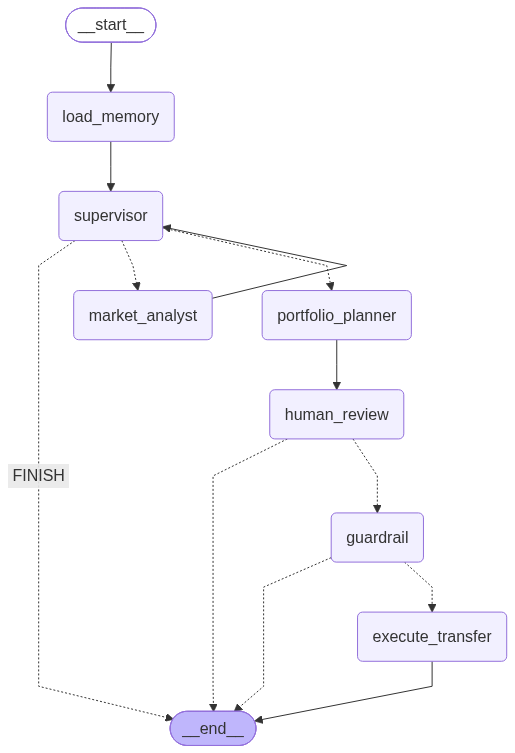

저장: ppt_assets/task2_graph.png


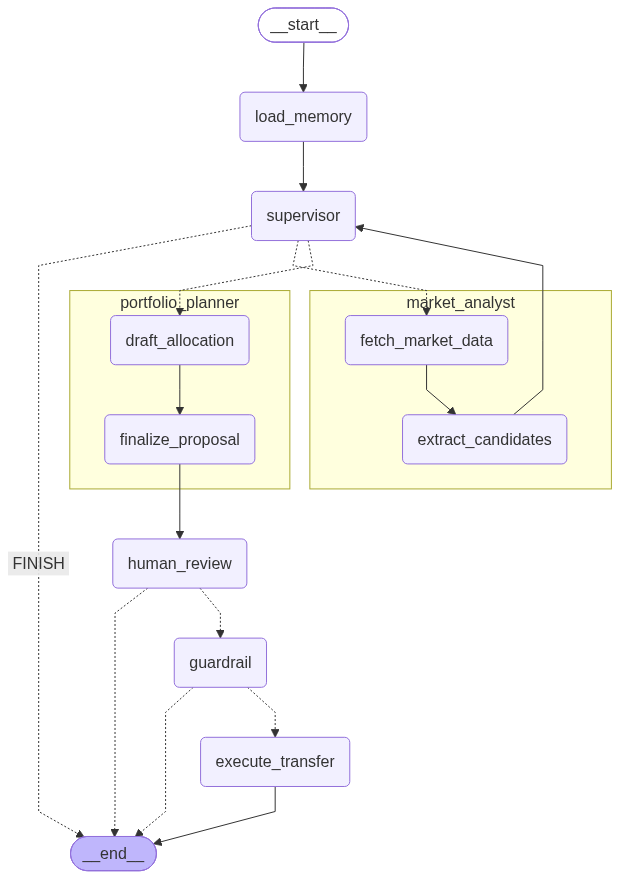

저장: ppt_assets/task2_graph_xray.png


In [11]:
save_graph(app, "ppt_assets/task2_graph.png")
save_graph(app, "ppt_assets/task2_graph_xray.png", xray=True)   # 서브그래프 내부까지 펼친 그림

## 7. 실행 헬퍼 : 노드별 State 변화 / 인터럽트 로깅, 타임 트래블

In [12]:
def short(v, n=50):
    return cut(v if isinstance(v, str) else json.dumps(v, ensure_ascii=False), n)

def run(inp, config):
    """stream 으로 실행하며 노드별 State 변화와 인터럽트 발생 시점을 기록"""
    prev = {**app.get_state(config).values, **(inp if isinstance(inp, dict) else {})}   # 입력값은 변경으로 보지 않음
    for chunk in app.stream(inp, config, stream_mode="updates"):
        for node, delta in chunk.items():
            if node == "__interrupt__":
                p = delta[0].value
                audit("INTERRUPT", node="human_review", amount=f"{p['invest_amount']:,}원", message=p["message"])
                for o in p["allocations"]:
                    logger.info("    제안: %s %s%% %s원 | %s", o["name"], o["weight"], f"{o['amount']:,}", cut(o["rationale"], 40))
                continue
            changed = {k: v for k, v in (delta or {}).items() if prev.get(k) != v}
            if changed:
                audit("STATE_UPDATE", node=node, changes={k: short(v) for k, v in changed.items()})
            prev.update(delta or {})
    snap = app.get_state(config)
    print(f"\n현재 상태: approval_status={snap.values.get('approval_status')} | 다음 노드={snap.next or 'END'}")
    return snap

def time_travel(config, node, updates):
    """과거 체크포인트 중 `node` 실행 직전 시점을 찾아 State 를 수정한 분기(fork) 생성"""
    history = list(app.get_state_history(config))
    print("체크포인트 이력 (최신 -> 과거)")
    for h in history:
        print(f"  step={h.metadata.get('step'):>2} | next={h.next} | id={h.config['configurable']['checkpoint_id'][:13]}")
    target = next(h for h in history if h.next == (node,))
    audit("TIME_TRAVEL", to=f"{node} 실행 직전", step=target.metadata.get("step"),
          checkpoint=target.config["configurable"]["checkpoint_id"][:13])
    return app.update_state(target.config, updates, as_node="market_analyst")   # market_analyst 가 끝난 직후로 간주 -> 다음은 supervisor

## 8. 시나리오 ① 제안 → 잘못된 입력(검증 루프) → 반려(후보군에 없는 금 요청) → 타임 트래블 → supervisor 재분석 판단 → 재제안 → 승인 → 송금

In [13]:
config = {"configurable": {"thread_id": "pf-001", "user_id": "user_001"}}
customer_input = {
    "customer": {"name": "김고객", "age": 34, "goal": "5년 내 주택 자금 마련"},
    "assets": {"cash": 80_000_000, "holdings": {"미국 S&P500 ETF": 20_000_000}},
    "invest_amount": 20_000_000,
    "target_account": "110-23-456789",
}
logger.info("===== 시나리오 1: thread=pf-001 =====")
snap = run(customer_input, config)

14:28:32 | INFO    | ===== 시나리오 1: thread=pf-001 =====


14:28:32 | INFO    | [MEMORY_LOAD    ] user_id=user_001 | risk=중립형 | history_count=1


14:28:32 | INFO    | [STATE_UPDATE   ] node=load_memory | changes={'profile': '{"risk_profile": "중립형", "horizon": "3년 이상", "prefe...', 'approval_status': 'pending', 'rejection_count': '0', 'feedback': '', 'candidates': '[]', 'portfolio': '{}'}


14:28:32 | INFO    | [AGENT_SWITCH   ] frm=supervisor | to=market_analyst | by=code | reason=후보군 없음


14:28:32 | INFO    | [STATE_UPDATE   ] node=supervisor | changes={'next_agent': 'market_analyst'}


...

14:28:39 | INFO    |     제안: 국내 대형주 ETF 30.0% 6,000,000원 | 국내 대형주 ETF는 안정적인 수익과 적당한 변동성, 배당 수익도 기대 ...


14:28:39 | INFO    |     제안: 미국 배당성장 ETF 30.0% 6,000,000원 | 미국 배당성장 ETF는 배당 선호 고객에게 적합하며, 금리 인하기에 배당...


14:28:39 | INFO    |     제안: 국고채 10년 ETF 30.0% 6,000,000원 | 국고채 10년 ETF는 안정적인 채권 수익과 낮은 변동성으로 중립형 투자...


14:28:39 | INFO    |     제안: MMF(초단기채) 10.0% 2,000,000원 | 현금성 자산인 MMF는 대기자금 파킹에 적합하며, 안정적인 수익과 매우 ...



현재 상태: approval_status=pending | 다음 노드=('human_review',)


In [14]:
# 사유 없이 reject -> 검증 루프에서 재질문 (송금 단계로 넘어가지 않음)
snap = run(Command(resume={"action": "reject"}), config)

14:28:39 | INFO    | [INTERRUPT      ] node=human_review | amount=20,000,000원 | message=입력 오류({'action': 'reject'}): approve 또는 feedback 이 포함된 reject 만 허용됩니다.


14:28:39 | INFO    |     제안: 국내 대형주 ETF 30.0% 6,000,000원 | 국내 대형주 ETF는 안정적인 수익과 적당한 변동성, 배당 수익도 기대 ...


14:28:39 | INFO    |     제안: 미국 배당성장 ETF 30.0% 6,000,000원 | 미국 배당성장 ETF는 배당 선호 고객에게 적합하며, 금리 인하기에 배당...


14:28:39 | INFO    |     제안: 국고채 10년 ETF 30.0% 6,000,000원 | 국고채 10년 ETF는 안정적인 채권 수익과 낮은 변동성으로 중립형 투자...


14:28:39 | INFO    |     제안: MMF(초단기채) 10.0% 2,000,000원 | 현금성 자산인 MMF는 대기자금 파킹에 적합하며, 안정적인 수익과 매우 ...



현재 상태: approval_status=pending | 다음 노드=('human_review',)


In [15]:
# 사유를 포함한 반려(수정 제안)
snap = run(Command(resume={"action": "reject",
                           "feedback": "인플레이션 대비로 금을 10% 정도 넣고, 국내 주식 비중은 15% 이하로 줄여주세요."}), config)

14:28:39 | INFO    | [HUMAN_REJECT   ] feedback=인플레이션 대비로 금을 10% 정도 넣고, 국내 주식 비중은 15% 이하로 줄여주세요.


14:28:39 | INFO    | [STATE_UPDATE   ] node=human_review | changes={'approval_status': 'rejected', 'feedback': '인플레이션 대비로 금을 10% 정도 넣고, 국내 주식 비중은 15% 이하로 줄여주세요.'}



현재 상태: approval_status=rejected | 다음 노드=END


In [16]:
# 타임 트래블: 시장 분석이 끝나고 supervisor 가 판단하기 직전 시점으로 돌아가 반려 정보를 넣은 분기 생성
rejected = snap.values
fork_config = time_travel(config, "supervisor", {
    "feedback": rejected["feedback"],
    "portfolio": rejected["portfolio"],               # 반려된 제안을 참고 자료로 전달
    "rejection_count": rejected["rejection_count"] + 1,
    "approval_status": "rejected",
})
snap = run(None, fork_config)   # supervisor 판단 -> (재분석) -> 재제안 -> 다시 interrupt

체크포인트 이력 (최신 -> 과거)
  step= 6 | next=() | id=1f1cb7df-0b0a
  step= 5 | next=('human_review',) | id=1f1cb7df-0ad4
  step= 4 | next=('portfolio_planner',) | id=1f1cb7de-ed4b
  step= 3 | next=('supervisor',) | id=1f1cb7de-ed47
  step= 2 | next=('market_analyst',) | id=1f1cb7de-ca06
  step= 1 | next=('supervisor',) | id=1f1cb7de-ca04
  step= 0 | next=('load_memory',) | id=1f1cb7de-ca02
  step=-1 | next=('__start__',) | id=1f1cb7de-ca01
14:28:39 | INFO    | [TIME_TRAVEL    ] to=supervisor 실행 직전 | step=3 | checkpoint=1f1cb7de-ed47


14:28:40 | INFO    | [AGENT_SWITCH   ] frm=supervisor | to=market_analyst | by=llm | reason=고객이 금 자산을 10% 포함하기를 원하며, 현재 후보군에 금 관련 자산이 없어 후보군을 다시 선정해야 합니...


14:28:40 | INFO    | [STATE_UPDATE   ] node=supervisor | changes={'approval_status': 'rework'}


14:28:40 | INFO    | [BRIDGE         ] to=market_analyst | passed_fields=['profile', 'feedback'] | withheld=['assets', 'target_account']


14:28:40 | INFO    | [AGENT_START    ] agent=market_analyst/fetch_market_data | rows=8


...

14:28:45 | INFO    |     제안: 국내 대형주 ETF 15.0% 3,000,000원 | 국내 대형주 ETF 비중을 고객 요청에 맞춰 15% 이하로 제한하여 안정...


14:28:45 | INFO    |     제안: 미국 배당성장 ETF 35.0% 7,000,000원 | 배당 선호 고객에게 적합한 미국 배당성장 ETF 비중 확대, 금리 인하기...


14:28:45 | INFO    |     제안: 국고채 10년 ETF 30.0% 6,000,000원 | 안정적인 채권 수익과 낮은 변동성으로 중립형 투자자에게 적합한 국고채 1...


14:28:45 | INFO    |     제안: 미국 S&P500 ETF 10.0% 2,000,000원 | 미국 대형주 ETF로 안정적인 성장과 배당 수익 제공, 변동성 관리에 도...



현재 상태: approval_status=rejected | 다음 노드=('supervisor',)


In [17]:
# 고객 최종 승인 -> 가드레일 -> 송금/매입 -> END
snap = run(Command(resume={"action": "approve"}), config)
final = snap.values
print(f"\n거래ID: {final['tx_id']} | 잔여 현금: {final['assets']['cash']:,}원")
print("보유 자산:", json.dumps(final["assets"]["holdings"], ensure_ascii=False))

14:28:45 | INFO    | [HUMAN_APPROVE  ] amount=20,000,000원 | account=110-**-***789


14:28:45 | INFO    | [STATE_UPDATE   ] node=human_review | changes={'approval_status': 'approved'}


14:28:45 | INFO    | [GUARDRAIL_PASS ] amount=20,000,000원 | account=110-**-***789


14:28:45 | INFO    | [STATE_UPDATE   ] node=guardrail | changes={'guardrail': '{"passed": true, "violations": []}'}


14:28:45 | INFO    |     매수 체결: 금현물 2,000,000원 (10.0%)


...

14:28:45 | INFO    |     매수 체결: 국고채 10년 ETF 6,000,000원 (30.0%)


14:28:45 | INFO    |     매수 체결: 미국 S&P500 ETF 2,000,000원 (10.0%)


14:28:45 | INFO    | [TRANSFER_DONE  ] tx_id=TX-BED490C3 | amount=20,000,000원 | cash_after=60,000,000원 | memory=history 저장


14:28:45 | INFO    | [STATE_UPDATE   ] node=execute_transfer | changes={'assets': '{"cash": 60000000, "holdings": {"미국 S&P500 ETF": 2...', 'approval_status': 'completed', 'tx_id': 'TX-BED490C3'}



현재 상태: approval_status=completed | 다음 노드=END

거래ID: TX-BED490C3 | 잔여 현금: 60,000,000원
보유 자산: {"미국 S&P500 ETF": 22000000, "금현물": 2000000, "국내 대형주 ETF": 3000000, "미국 배당성장 ETF": 7000000, "국고채 10년 ETF": 6000000}


## 9. 시나리오 ② 가드레일 차단 (1회 한도 초과 + 신고 계좌) / 장기 메모리 재사용 확인

In [18]:
config2 = {"configurable": {"thread_id": "pf-002", "user_id": "user_001"}}
logger.info("===== 시나리오 2: thread=pf-002 (가드레일 검증) =====")
snap2 = run({**customer_input, "invest_amount": 50_000_000, "target_account": "999-99-999999"}, config2)
snap2 = run(Command(resume={"action": "approve"}), config2)
print("가드레일 결과:", snap2.values["guardrail"])

14:28:45 | INFO    | ===== 시나리오 2: thread=pf-002 (가드레일 검증) =====


14:28:45 | INFO    | [MEMORY_LOAD    ] user_id=user_001 | risk=중립형 | history_count=2


14:28:45 | INFO    | [STATE_UPDATE   ] node=load_memory | changes={'profile': '{"risk_profile": "중립형", "horizon": "3년 이상", "prefe...', 'approval_status': 'pending', 'rejection_count': '0', 'feedback': '', 'candidates': '[]', 'portfolio': '{}'}


14:28:45 | INFO    | [AGENT_SWITCH   ] frm=supervisor | to=market_analyst | by=code | reason=후보군 없음


14:28:45 | INFO    | [STATE_UPDATE   ] node=supervisor | changes={'next_agent': 'market_analyst'}


...


현재 상태: approval_status=pending | 다음 노드=('human_review',)
14:28:50 | INFO    | [HUMAN_APPROVE  ] amount=50,000,000원 | account=999-**-***999


14:28:50 | INFO    | [STATE_UPDATE   ] node=human_review | changes={'approval_status': 'approved'}


14:28:50 | INFO    | [GUARDRAIL_BLOCK] violations=['1회 한도 30,000,000원 초과', '비정상(신고) 계좌']


14:28:50 | INFO    | [STATE_UPDATE   ] node=guardrail | changes={'guardrail': '{"passed": false, "violations": ["1회 한도 30,000,000...', 'approval_status': 'blocked'}



현재 상태: approval_status=blocked | 다음 노드=END
가드레일 결과: {'passed': False, 'violations': ['1회 한도 30,000,000원 초과', '비정상(신고) 계좌']}


## 10. 가상 로그 시스템 요약 & 자체 점검

In [19]:
records = [json.loads(line) for line in open(AUDIT_PATH, encoding="utf-8")]
print(f"감사 로그 {len(records)}건: {AUDIT_PATH}")
print("이벤트별 건수:", {e: sum(r["event"] == e for r in records) for e in dict.fromkeys(r["event"] for r in records)})
assert not any(acc in line for line in open(AUDIT_PATH, encoding="utf-8") for acc in ("110-23-456789", "999-99-999999")), "계좌 원문 노출"

# 가드레일·주문 환산 로직 점검 (LLM 호출 없음)
_o = to_orders([{"ticker": "MMF", "weight": 1}, {"ticker": "GOLD", "weight": 2}], 10_000_000)
assert sum(o["amount"] for o in _o) == 10_000_000
assert check_guardrails(10_000_000, 80_000_000, "110-23-456789", _o) == []
assert "1회 한도 30,000,000원 초과" in check_guardrails(50_000_000, 80_000_000, "110-23-456789", to_orders(_o, 50_000_000))
assert "비정상(신고) 계좌" in check_guardrails(10_000_000, 80_000_000, "999-99-999999", _o)
assert "계좌 형식 오류" in check_guardrails(10_000_000, 80_000_000, "12345", _o)
assert any("회피 자산" in v for v in check_guardrails(10_000_000, 80_000_000, "110-23-456789",
                                                     to_orders([{"ticker": "SEMI_2X", "weight": 1}], 10_000_000), "레버리지·가상자산"))
assert final["approval_status"] == "completed" and snap2.values["approval_status"] == "blocked"
llm_routes = [r for r in records if r["event"] == "AGENT_SWITCH" and r.get("by") == "llm"]
assert len(llm_routes) == 1, "supervisor LLM 은 반려 1회에서만 호출되어야 함"
print("점검 통과 (로그 파일: ppt_assets/task2_run.log)")

감사 로그 54건: ppt_assets/task2_audit_log.jsonl
이벤트별 건수: {'MEMORY_LOAD': 2, 'STATE_UPDATE': 20, 'AGENT_SWITCH': 6, 'BRIDGE': 3, 'AGENT_START': 6, 'AGENT_DONE': 6, 'INTERRUPT': 4, 'HUMAN_REJECT': 1, 'TIME_TRAVEL': 1, 'HUMAN_APPROVE': 2, 'GUARDRAIL_PASS': 1, 'TRANSFER_DONE': 1, 'GUARDRAIL_BLOCK': 1}
점검 통과 (로그 파일: ppt_assets/task2_run.log)
